### 1. Imports & chargement des données

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.svm import LinearSVC
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, 
    f1_score, recall_score, make_scorer,
    precision_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

df_train = pd.read_csv("../data/weatherAUS_train.csv")
df_test = pd.read_csv("../data/weatherAUS_test.csv")

### 2. Encodage des variables catégorielles

In [2]:
# Encodage des variables catégorielles
cat_cols = df_train.select_dtypes(include=['object', 'bool']).columns.difference(['Date', 'RainTomorrow'])
print(f"Colonnes catégorielles : {list(cat_cols)}")

le = LabelEncoder()
for col in cat_cols:
    df_train[col] = le.fit_transform(df_train[col].astype(str))
    df_test[col] = le.transform(df_test[col].astype(str))

/tmp/ipykernel_51774/2648102147.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object', 'bool']).columns.difference(['Date', 'RainTomorrow'])


Colonnes catégorielles : ['Location', 'RainToday', 'WindDir3pm', 'WindDir9am', 'WindGustDir', 'weather_trend_group']


### 3. Séparation des features et de la variable cible

In [3]:
# Colonnes à exclure
cols_to_drop = ['Date', 'Location', 'RainTomorrow', 'weather_trend_group']

# Séparation features / cible
X_train = df_train.drop(columns=cols_to_drop)
y_train = df_train['RainTomorrow'].astype(int)

X_test = df_test.drop(columns=cols_to_drop)
y_test = df_test['RainTomorrow'].astype(int)

print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")

X_train : (111056, 29)
X_test  : (27764, 29)


### 4. Scaling

In [ ]:
# scaler = StandardScaler()
# X_train_scaled = scaler.fit_transform(X_train)
# X_test_scaled = scaler.transform(X_test)

### 5. Entraînement du modèle de base (LinearSVC)

In [5]:
model = LinearSVC(class_weight='balanced', random_state=42, max_iter=2000)
model.fit(X_train_scaled, y_train)

y_pred_train = model.predict(X_train_scaled)
y_pred_test = model.predict(X_test_scaled)

y_score_train = model.decision_function(X_train_scaled)
y_score_test  = model.decision_function(X_test_scaled)

#### 5.1 Métriques (F1, Recall, Précision, AUC-ROC, PR-AUC)

In [6]:
# Métriques du LinearSVC
f1_macro_train = f1_score(y_train, y_pred_train, average='macro')
f1_macro_test  = f1_score(y_test,  y_pred_test,  average='macro')

recall_train   = recall_score(y_train, y_pred_train)
recall_test    = recall_score(y_test,  y_pred_test)

prec_train     = precision_score(y_train, y_pred_train)
prec_test      = precision_score(y_test,  y_pred_test)

auc_roc_train  = roc_auc_score(y_train, y_score_train)
auc_roc_test   = roc_auc_score(y_test,  y_score_test)

pr_auc_train   = average_precision_score(y_train, y_score_train)
pr_auc_test    = average_precision_score(y_test,  y_score_test)

In [7]:
sep = "─" * 52
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LinearSVC':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score Macro':<28} {f1_macro_train:>10.4f} {f1_macro_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)
print("\n")
print(sep)
print("Le F1 macro moyenne les deux classes équitablement.")
print(sep)
print("Le class_weight='balanced' a clairement orienté le modèle vers un recall élevé.")
print("La précision est faible avec presque 1 prédiction Yes sur 2 qui est une fausse alerte.") 
print("Ce compromis est courant pour les problèmes météo où manquer une pluie est pire que signaler un faux positif.")
print(sep)
print("Le AUC-ROC (~0.86) signifie que le modèle discrimine bien les jours de pluie des jours secs dans 86% des cas.")
print("Le PR-AUC (~0.68) montre que le modèle a du mal à faire le lien entre les prédictions positives et les vraies pluies.")
print(sep)
print("Le LinearSVC avec class_weight='balanced' est un bon modèle de base avec un excellent recall mais une précision à améliorer.")
print("L'écart entre train et test est faible pour toutes les métriques, écartant l'idée d'un surapprentissage du modèle.")
print(sep)

────────────────────────────────────────────────────
          ÉVALUATION DU MODÈLE — LinearSVC          
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score Macro                   0.7441     0.7522
────────────────────────────────────────────────────
Recall  (classe Yes)             0.7735     0.7802
Précision (classe Yes)           0.5279     0.5400
────────────────────────────────────────────────────
AUC-ROC                          0.8742     0.8794
PR-AUC                           0.6995     0.7101
────────────────────────────────────────────────────


────────────────────────────────────────────────────
Le F1 macro moyenne les deux classes équitablement.
────────────────────────────────────────────────────
Le class_weight='balanced' a clairement orienté le modèle vers un recall élevé.
La précision est faible avec presque 1 prédiction Yes sur 2 qui est une fausse aler

#### 5.2 Matrice de confusion

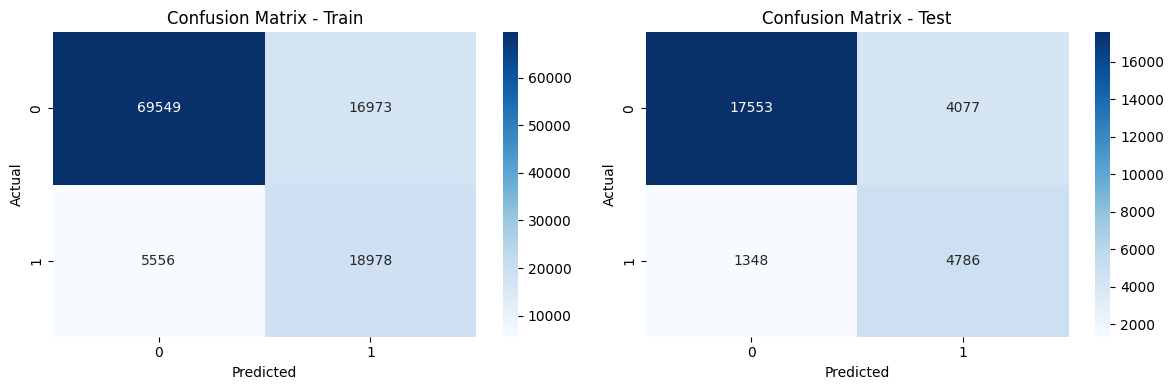

────────────────────────────────────────────────────
Classe No (pas de pluie)
Le modèle se trompe beaucoup sur les jours secs : il prédit Yes pour ~17k jours secs sur le train et ~4.4k sur le test.
C'est le coût direct du class_weight='balanced' où le modèle est poussé à détecter la pluie même au prix de fausses alertes sur les jours secs.
────────────────────────────────────────────────────
Classe Yes (pluie)
Le modèle détecte bien les jours de pluie : seulement 5 471 jours de pluie ratés sur le train (FN), soit un recall de ~77%.
C'est l'objectif voulu où manquer une pluie est plus coûteux que déclencher une fausse alerte.
────────────────────────────────────────────────────
Cohérence Train VS Test
Les proportions sont très stables entre train et test, ce qui confirme l'absence d'overfitting.
────────────────────────────────────────────────────


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y_pred, title in zip(axes, [y_pred_train, y_pred_test], ['Train', 'Test']):
    cm = confusion_matrix(y_train if title == 'Train' else y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(f'Confusion Matrix - {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

sep = "─" * 52
print(sep)
print("Classe No (pas de pluie)")
print("Le modèle se trompe beaucoup sur les jours secs : il prédit Yes pour ~17k jours secs sur le train et ~4.4k sur le test.")
print("C'est le coût direct du class_weight='balanced' où le modèle est poussé à détecter la pluie même au prix de fausses alertes sur les jours secs.")
print(sep)
print("Classe Yes (pluie)")
print("Le modèle détecte bien les jours de pluie : seulement 5 471 jours de pluie ratés sur le train (FN), soit un recall de ~77%.")
print("C'est l'objectif voulu où manquer une pluie est plus coûteux que déclencher une fausse alerte.")
print(sep)
print("Cohérence Train VS Test")
print("Les proportions sont très stables entre train et test, ce qui confirme l'absence d'overfitting.")
print(sep)

#### 5.3 Courbes AUC-ROC et PR-AUC

AUC-ROC - Train : 0.8742 | Test : 0.8794


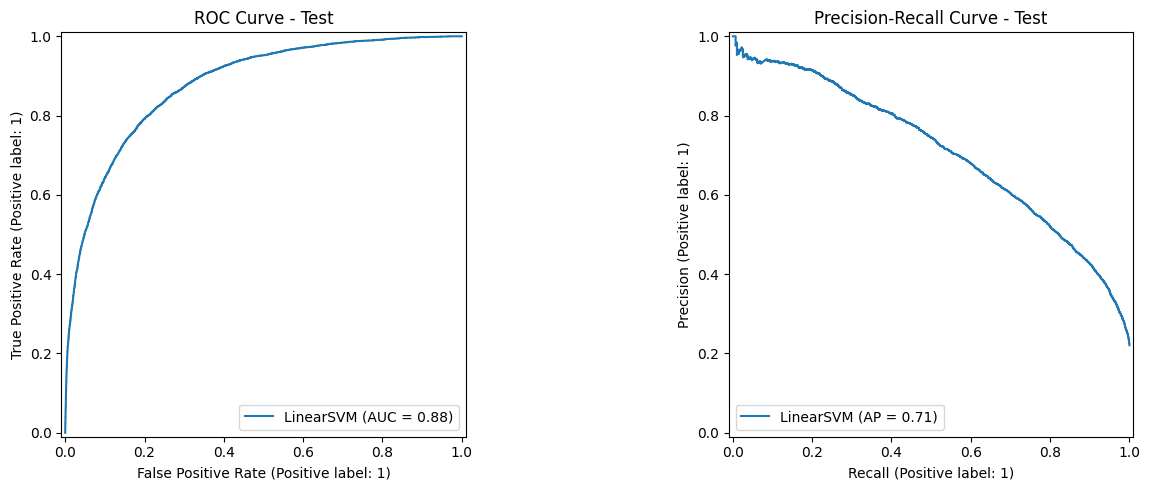

────────────────────────────────────────────────────
La courbe ROC trace les vrais positifs vs les faux positifs pour tous les seuils de décision possibles.
Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle.
────────────────────────────────────────────────────
La courbe PR trace la précision vs le rappel pour tous les seuils de décision possibles.
Plus la courbe est proche du coin supérieur droit, meilleur est le modèle.
────────────────────────────────────────────────────


In [9]:
print(f"AUC-ROC - Train : {roc_auc_score(y_train, y_score_train):.4f} | Test : {roc_auc_score(y_test, y_score_test):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
RocCurveDisplay.from_predictions(y_test, y_score_test, ax=axes[0], name='LinearSVM')
axes[0].set_title('ROC Curve - Test')
PrecisionRecallDisplay.from_predictions(y_test, y_score_test, ax=axes[1], name='LinearSVM')
axes[1].set_title('Precision-Recall Curve - Test')
plt.tight_layout()
plt.show()

print(sep)
print("La courbe ROC trace les vrais positifs vs les faux positifs pour tous les seuils de décision possibles.")
print("Plus la courbe est proche du coin supérieur gauche, meilleur est le modèle.")
print(sep)
print("La courbe PR trace la précision vs le rappel pour tous les seuils de décision possibles.")
print("Plus la courbe est proche du coin supérieur droit, meilleur est le modèle.")
print(sep)

#### 5.4 Courbe Précision / Recall vs Seuil

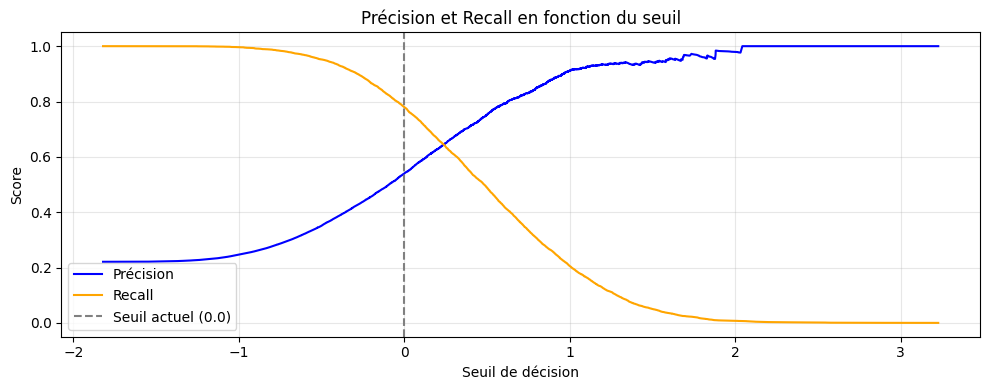

In [10]:
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test, y_score_test)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, precisions[:-1], label='Précision', color='blue')
plt.plot(thresholds, recalls[:-1],    label='Recall',    color='orange')
plt.axvline(x=0, color='gray', linestyle='--', label='Seuil actuel (0.0)')
plt.xlabel('Seuil de décision')
plt.ylabel('Score')
plt.title('Précision et Recall en fonction du seuil')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### 5.6 Importance des features

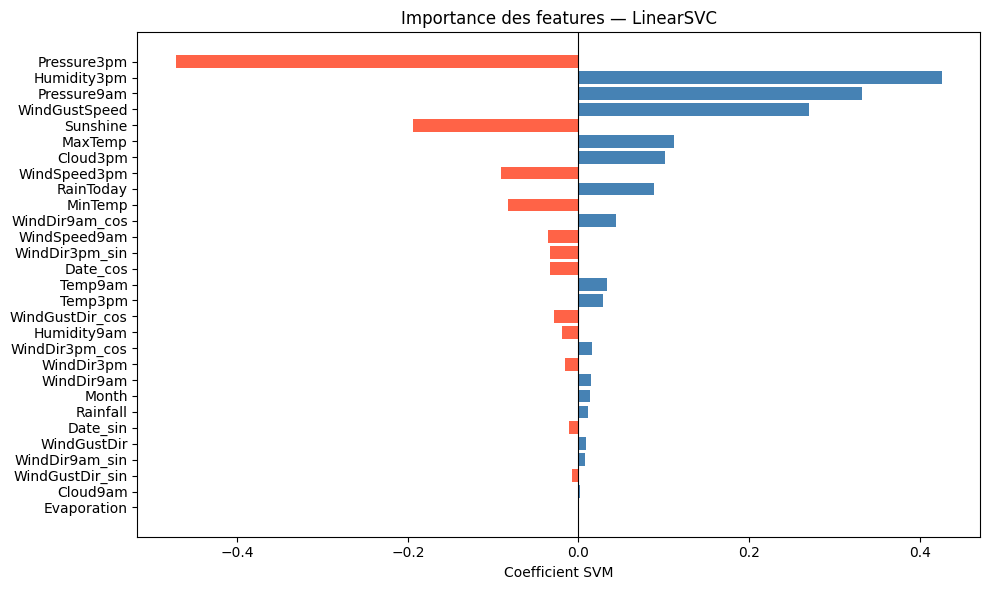

In [11]:
feature_names = X_train.columns
coefficients  = model.coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coef': coefficients})
coef_df = coef_df.reindex(coef_df['coef'].abs().sort_values(ascending=False).index)

plt.figure(figsize=(10, 6))
colors = ['tomato' if c < 0 else 'steelblue' for c in coef_df['coef']]
plt.barh(coef_df['feature'], coef_df['coef'], color=colors)
plt.axvline(x=0, color='black', linewidth=0.8)
plt.xlabel('Coefficient SVM')
plt.title('Importance des features — LinearSVC')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Un coefficient positif (bleu) signifie "quand cette feature augmente, la probabilité de pluie augmente". 

Un coefficient négatif (rouge) signifie "quand cette feature augmente, la probabilité de pluie diminue".

#### 5.7 Courbe d'apprentissage (Learning Curve)

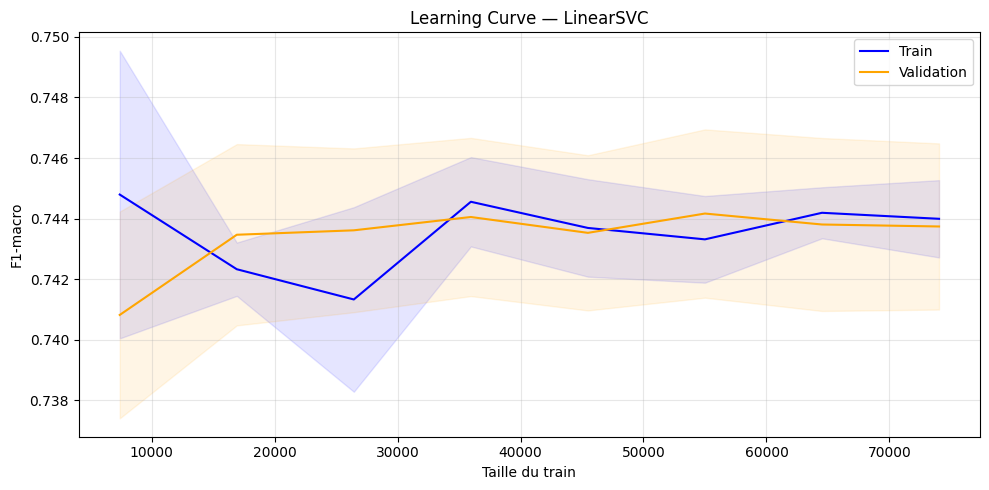

In [12]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    model, X_train_scaled, y_train,
    train_sizes=np.linspace(0.1, 1.0, 8),
    scoring='f1_macro', cv=3, n_jobs=-1
)

plt.figure(figsize=(10, 5))
plt.plot(train_sizes, train_scores.mean(axis=1), label='Train',      color='blue')
plt.plot(train_sizes, val_scores.mean(axis=1),   label='Validation', color='orange')
plt.fill_between(train_sizes,
                 train_scores.mean(axis=1) - train_scores.std(axis=1),
                 train_scores.mean(axis=1) + train_scores.std(axis=1), alpha=0.1, color='blue')
plt.fill_between(train_sizes,
                 val_scores.mean(axis=1) - val_scores.std(axis=1),
                 val_scores.mean(axis=1) + val_scores.std(axis=1), alpha=0.1, color='orange')
plt.xlabel('Taille du train')
plt.ylabel('F1-macro')
plt.title('Learning Curve — LinearSVC')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

L'encodage cyclique (Date_sin/cos, WindDir_sin/cos) a rendu les features plus informatives pour un modèle linéaire.

Le score final reste similaire (~0.744 F1-macro), mais le modèle atteint désormais ce plateau dès 8 000 échantillons, contre ~50 000 précédemment, et l'écart train/validation a quasi disparu. 

Cela indique que l'encodage cyclique fournit au modèle linéaire une représentation directement exploitable des features circulaires.



### 6. Optimisation des hyperparamètres (Grid Search)

#### 6.1 Pipeline + Grid Search

In [ ]:
# Pipeline : Scaler + LinearSVC 
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('model',  LinearSVC(random_state=42, max_iter=5000))
])

# Grille d'hyperparamètres
# C : régularisation (petit = plus régularisé, grand = moins régularisé)
# loss : hinge (SVM classique) ou squared_hinge (plus stable, par défaut)
param_grid = {
    'model__C':            [0.01, 0.1, 1, 10],
    'model__loss':         ['hinge', 'squared_hinge'],
    'model__class_weight': ['balanced'],
}

# Cross-validation stratifiée (respecte la distribution des classes)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Scorer : F1-macro (insensible au déséquilibre)
scorer = make_scorer(f1_score, average='macro')

# Grid Search
grid_search = GridSearchCV(
    estimator  = pipe, 
    param_grid = param_grid, 
    scoring    = scorer, 
    cv         = cv, 
    n_jobs     = -1, 
    refit      = True 
)
grid_search.fit(X_train, y_train)

/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/nicolas/Bureau/alternance/juin25_alt2_mle_meteo/venv/lib/python3.12/site-packages/sklearn/svm/_base.py:1258: ConvergenceWarnin

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__class_weight': ['balanced'], 'model__loss': ['hinge', 'squared_hinge']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(f...average=macro)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the co

#### 6.2 Résultats & meilleurs paramètres

In [14]:
# Résultats des meilleurs hyperparamètres
sep = "─" * 52
print(f"\n{'GRID SEARCH — Meilleurs hyperparamètres':^52}")
print(sep)
for param, value in grid_search.best_params_.items():
    print(f"  {param:<35} {str(value):>12}")
print(sep)

# Évaluation du meilleur modèle
best_model = grid_search.best_estimator_
y_pred_test_gs  = best_model.predict(X_test)
y_pred_train_gs = best_model.predict(X_train)

# Scores du meilleur modèle
y_score_train_gs = best_model.decision_function(X_train)
y_score_test_gs  = best_model.decision_function(X_test)

# Métriques du meilleur modèle
f1_macro_train_gs = f1_score(y_train, y_pred_train_gs, average='macro')
f1_macro_test_gs  = f1_score(y_test,  y_pred_test_gs,  average='macro')

recall_train_gs  = recall_score(y_train, y_pred_train_gs)
recall_test_gs   = recall_score(y_test,  y_pred_test_gs)

prec_train_gs    = precision_score(y_train, y_pred_train_gs)
prec_test_gs     = precision_score(y_test,  y_pred_test_gs)

auc_roc_train_gs = roc_auc_score(y_train, y_score_train_gs)
auc_roc_test_gs  = roc_auc_score(y_test,  y_score_test_gs)

pr_auc_train_gs  = average_precision_score(y_train, y_score_train_gs)
pr_auc_test_gs   = average_precision_score(y_test,  y_score_test_gs)



      GRID SEARCH — Meilleurs hyperparamètres       
────────────────────────────────────────────────────
  model__C                                      10
  model__class_weight                     balanced
  model__loss                                hinge
────────────────────────────────────────────────────


#### 6.3 Comparaison Base vs Grid Search

In [15]:
print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LinearSVC':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score Macro':<28} {f1_macro_train:>10.4f} {f1_macro_test:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train:>10.4f} {recall_test:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train:>10.4f} {prec_test:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train:>10.4f} {auc_roc_test:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train:>10.4f} {pr_auc_test:>10.4f}")
print(sep)
print("\n")

print(sep)
print(f"{'ÉVALUATION DU MODÈLE — LinearSVC Grid Search':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score Macro':<28} {f1_macro_train_gs:>10.4f} {f1_macro_test_gs:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train_gs:>10.4f} {recall_test_gs:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train_gs:>10.4f} {prec_test_gs:>10.4f}")
print(sep)
print(f"{'AUC-ROC':<28} {auc_roc_train_gs:>10.4f} {auc_roc_test_gs:>10.4f}")
print(f"{'PR-AUC':<28} {pr_auc_train_gs:>10.4f} {pr_auc_test_gs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
          ÉVALUATION DU MODÈLE — LinearSVC          
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score Macro                   0.7441     0.7522
────────────────────────────────────────────────────
Recall  (classe Yes)             0.7735     0.7802
Précision (classe Yes)           0.5279     0.5400
────────────────────────────────────────────────────
AUC-ROC                          0.8742     0.8794
PR-AUC                           0.6995     0.7101
────────────────────────────────────────────────────


────────────────────────────────────────────────────
    ÉVALUATION DU MODÈLE — LinearSVC Grid Search    
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score Macro                   0.7446     0.7513
───────

In [16]:
print(sep)
print("En comparant les métriques avant et après la Grid Search, on remarque que l'impact de l'optimisation des hyperparamètres est nul.")
print("Le class_weight='balanced' est clairement le paramètre dominant qui a orienté le modèle vers un recall élevé.")
print("Le LinearSVC plafonne à F1-macro~0.74 et AUC~0.86 ce qui est plutôt un résultat solide pour un modèle linéaire.") 
print(sep)

────────────────────────────────────────────────────
En comparant les métriques avant et après la Grid Search, on remarque que l'impact de l'optimisation des hyperparamètres est nul.
Le class_weight='balanced' est clairement le paramètre dominant qui a orienté le modèle vers un recall élevé.
Le LinearSVC plafonne à F1-macro~0.74 et AUC~0.86 ce qui est plutôt un résultat solide pour un modèle linéaire.
────────────────────────────────────────────────────


### 7. Seuil personnalisé (sur le meilleur modèle)

In [17]:
# Scan des seuils pour choisir le meilleur
print(sep)
print(f"{'SCAN DES SEUILS — Meilleur modèle Grid Search':^52}")
print(sep)
print(f"{'Seuil':<10} {'Recall':>10} {'Précision':>10} {'F1-macro':>10}")
print(sep)
for s in [-0.1, -0.2, -0.3, -0.4, -0.5]:
    y_pred_s = (y_score_test_gs >= s).astype(int)
    print(f"{s:<10} {recall_score(y_test, y_pred_s):>10.4f} "
          f"{precision_score(y_test, y_pred_s):>10.4f} "
          f"{f1_score(y_test, y_pred_s, average='macro'):>10.4f}")
print(sep)
print("\n")

# Application du seuil personnalisé choisi
seuil = -0.1
y_pred_custom_gs = (y_score_test_gs >= seuil).astype(int)

print(sep)
print(f"{'IMPACT DU SEUIL PERSONNALISÉ (Grid Search)':^52}")
print(sep)
print(f"{'Métrique':<28} {'Défaut (0.0)':>10} {f'Seuil {seuil}':>10}")
print(sep)
print(f"{'Recall (Yes)':<28} {recall_score(y_test, y_pred_test_gs):>10.4f} "
      f"{recall_score(y_test, y_pred_custom_gs):>10.4f}")
print(f"{'Précision (Yes)':<28} {precision_score(y_test, y_pred_test_gs):>10.4f} "
      f"{precision_score(y_test, y_pred_custom_gs):>10.4f}")
print(f"{'F1-macro':<28} {f1_score(y_test, y_pred_test_gs, average='macro'):>10.4f} "
      f"{f1_score(y_test, y_pred_custom_gs, average='macro'):>10.4f}")
print(sep)
print(f"{'AUC-ROC (inchangé)':<28} {auc_roc_test_gs:>10.4f} {auc_roc_test_gs:>10.4f}")
print(f"{'PR-AUC  (inchangé)':<28} {pr_auc_test_gs:>10.4f} {pr_auc_test_gs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
   SCAN DES SEUILS — Meilleur modèle Grid Search    
────────────────────────────────────────────────────
Seuil          Recall  Précision   F1-macro
────────────────────────────────────────────────────
-0.1           0.8024     0.5168     0.7414
-0.2           0.8246     0.4983     0.7320
-0.3           0.8466     0.4786     0.7202
-0.4           0.8662     0.4615     0.7084
-0.5           0.8847     0.4430     0.6938
────────────────────────────────────────────────────


────────────────────────────────────────────────────
     IMPACT DU SEUIL PERSONNALISÉ (Grid Search)     
────────────────────────────────────────────────────
Métrique                     Défaut (0.0) Seuil -0.1
────────────────────────────────────────────────────
Recall (Yes)                     0.7811     0.8024
Précision (Yes)                  0.5383     0.5168
F1-macro                         0.7513     0.7414
───────────────────────────────────────────────────

In [18]:
print(sep)
print("En choisissant un seuil plus permissif (ex: -0.1), on peut augmenter le recall au prix d'une légère baisse de précision.")
print("Le F1-macro reste relativement stable, ce qui indique un bon compromis entre recall et précision.")
print(sep)

────────────────────────────────────────────────────
En choisissant un seuil plus permissif (ex: -0.1), on peut augmenter le recall au prix d'une légère baisse de précision.
Le F1-macro reste relativement stable, ce qui indique un bon compromis entre recall et précision.
────────────────────────────────────────────────────


In [19]:
# ── Prédictions avec le seuil personnalisé ────────────────────────────────────
seuil = -0.1
y_pred_custom_train = (y_score_train_gs >= seuil).astype(int)
y_pred_custom_test  = (y_score_test_gs  >= seuil).astype(int)

# ── Métriques du modèle avec seuil personnalisé ───────────────────────────────
# AUC-ROC et PR-AUC : inchangées (indépendantes du seuil)
# On réutilise y_score_train_gs et y_score_test_gs déjà calculés

f1_macro_train_custom = f1_score(y_train, y_pred_custom_train, average='macro')
f1_macro_test_custom  = f1_score(y_test,  y_pred_custom_test,  average='macro')

recall_train_custom   = recall_score(y_train, y_pred_custom_train)
recall_test_custom    = recall_score(y_test,  y_pred_custom_test)

prec_train_custom     = precision_score(y_train, y_pred_custom_train)
prec_test_custom      = precision_score(y_test,  y_pred_custom_test)

In [20]:
print(sep)
print(f"{'ÉVALUATION — LinearSVC GS + Seuil -0.1':^52}")
print(sep)
print(f"{'Métrique':<28} {'Train':>10} {'Test':>10}")
print(sep)
print(f"{'F1-score Macro':<28} {f1_macro_train_custom:>10.4f} {f1_macro_test_custom:>10.4f}")
print(sep)
print(f"{'Recall  (classe Yes)':<28} {recall_train_custom:>10.4f} {recall_test_custom:>10.4f}")
print(f"{'Précision (classe Yes)':<28} {prec_train_custom:>10.4f} {prec_test_custom:>10.4f}")
print(sep)
print(f"{'AUC-ROC (inchangé)':<28} {auc_roc_train_gs:>10.4f} {auc_roc_test_gs:>10.4f}")
print(f"{'PR-AUC  (inchangé)':<28} {pr_auc_train_gs:>10.4f} {pr_auc_test_gs:>10.4f}")
print(sep)

────────────────────────────────────────────────────
       ÉVALUATION — LinearSVC GS + Seuil -0.1       
────────────────────────────────────────────────────
Métrique                          Train       Test
────────────────────────────────────────────────────
F1-score Macro                   0.7354     0.7414
────────────────────────────────────────────────────
Recall  (classe Yes)             0.7993     0.8024
Précision (classe Yes)           0.5081     0.5168
────────────────────────────────────────────────────
AUC-ROC (inchangé)               0.8742     0.8794
PR-AUC  (inchangé)               0.6982     0.7088
────────────────────────────────────────────────────
